In [1]:
import pandas as pd
# df = pd.read_csv('C:/users/arj26323/OneDrive - University of Georgia/Documents/Manuscripts/Network analysis/News articles/data/Test.csv', encoding='cp1252')
# df = pd.read_csv('C:/users/arj26323/OneDrive - University of Georgia/Documents/Manuscripts/Network analysis/News articles/data/restoration_news.csv', encoding="utf-8")
df = pd.read_csv('C:/users/arj26323/OneDrive - University of Georgia/Documents/Manuscripts/Network analysis/News articles/data/annotated_restoration_news.csv', encoding="utf-8")

df

,Title,FullText,Abstract,Annotation,StoreId,ArticleType,Authors,companies,copyright,documentType,...,notes,startPage,subjectClassifications,subjectTerms,subjects,FindACopy,Database,sentiment,analysis_text,masked_text
0,Port project's spiraling price,Costs keep rising to deepen the Savannah River...,Mitigate environmental damage Some Items On ...,Critical,963465691,newspapers,NaN,NaN,"(Copyright , The Atlanta Journal-Constitution...",News,...,NaN,A.8,NaN,NaN,NaN,https://galileo-uga.primo.exlibrisgroup.com/op...,"Global Newsstream Collection, U.S. Newsstream ...",positive,Costs keep rising to deepen the Savannah River...,Costs keep rising to deepen the Savannah River...
1,BRYAN COUNTY NOW DECEMBER STUDENT OF THE MONTH...,NaN,"/b&gt; ""I enjoy decorating the Christmas tree ...",Neutral,821863487,newspapers,BRYAN COUNTY NOW,NaN,(Copyright 2010 Savannah Morning News.),News,...,NaN,A.6,NaN,"Morales, Crystal , Johnson, Joye , Fay, Veron...",NaN,https://galileo-uga.primo.exlibrisgroup.com/op...,"Global Newsstream Collection, U.S. Newsstream ...",positive,"/b&gt; ""I enjoy decorating the Christmas tree ...","/b&gt; ""I enjoy decorating the Christmas tree ..."
2,Program spurs oyster reef restoration,Nov. 06--When people shuck oyster shells at Co...,"In addition to using restaurant donations, the...",Supportive,762549499,newspapers,"Fakour, Shanessa",NaN,To see more of The Brunswick News or to subsc...,News,...,NaN,n/a,"72251 Restaurants and Other Eating Places , 5...","SUSTAINABILITY , INDUSTRY , SUSTAINABILITY , ...",NaN,https://galileo-uga.primo.exlibrisgroup.com/op...,"Global Newsstream Collection, U.S. Newsstream ...",positive,Nov. 06--When people shuck oyster shells at Co...,Nov. 06--When people shuck oyster shells at Co...
3,SPEND A SATURDAY ON MARINE SCIENCE,NaN,"""My classic all-time most-hated one is droppin...",Neutral,757027518,newspapers,"Landers, Mary",NaN,(Copyright 2010 Savannah Morning News.),News,...,NaN,E.10,NaN,"Savidge, Bill",NaN,https://galileo-uga.primo.exlibrisgroup.com/op...,"Global Newsstream Collection, U.S. Newsstream ...",positive,"""My classic all-time most-hated one is droppin...","""My classic all-time most-hated one is droppin..."
4,AQUARIUM FREE FOR ONE DAY,NaN,The University of Georgia Marine Extension Ser...,Neutral,756925019,newspapers,NaN,NaN,(Copyright 2010 Savannah Morning News.),News,...,NaN,A.9,NaN,NaN,NaN,https://galileo-uga.primo.exlibrisgroup.com/op...,"Global Newsstream Collection, U.S. Newsstream ...",positive,The University of Georgia Marine Extension Ser...,The University of Georgia Marine Extension Ser...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
62,"Southern Company, partners to award Five Star ...","ATLANTA, Aug. 5, 2014 /PRNewswire/ -- Southern...","Since 2006, Southern Company has contributed m...",Supportive,1551178711,newspapers,NaN,"Southern Co , Birmingham-Southern College , A...","Copyright PR Newswire Association LLC Aug 5, ...",News,...,NaN,n/a,NaN,"SUSTAINABILITY , SUSTAINABILITY , SUSTAINABIL...",NaN,https://galileo-uga.primo.exlibrisgroup.com/op...,"Global Newsstream Collection, U.S. Newsstream ...",positive,"ATLANTA, Aug. 5, 2014 /PRNewswire/ -- Southern...","ATLANTA, Aug. 5, 2014 /PRNewswire/ -- Southern..."
63,Former New Smyrna high school field being rest...,NEW SMYRNA BEACH\n\nAn empty field on the site...,Tractors began scraping away grass and soil ...,Supportive,1544010721,newspapers,Dinah Voyles Pulver,Costa Del Mar,"Copyright Halifax Media Group Jul 09, 2014",News,...,NaN,n/a,NaN,"Haydt, Paul",NaN,https://galileo-uga.primo.exlibrisgroup.com/op...,"Global Newsstream Collection, U.S. Newsstream ...",positive,NEW SMYRNA BEACH\n\nAn empty field on the site...,NEW SMYRNA BEACH\n\nAn empty field on the site...
64,CONGRESS COMES TO THE COAST,NaN,"""For 97 percent of us who study and write pa...",Neutral,1521838754,newspapers,"Landers, Mary",American Meteorological Society,(Copyright 2014 Savannah Morning News.),News,...,NaN,A.1

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set your plotting style
sns.set_theme(style="white")

# Count occurrences per year and sort chronologically
yearly_counts = df['year'].value_counts().sort_index()

# # Plotting
# plt.figure(figsize=(12, 6))
# ax = sns.barplot(x=yearly_counts.index, y=yearly_counts.values, color="black")

# plt.xlabel("Year", fontsize=12)
# plt.ylabel("Number of Articles", fontsize=12)

# # Rotate x-axis labels if you have many years, so they don't crowd
# plt.xticks(rotation=45)
# plt.tight_layout()
# plt.show()

sentiment
positive    57
neutral      8
negative     2
Name: count, dtype: int64
Annotation
Supportive    48
Neutral       18
Critical       1
Name: count, dtype: int64


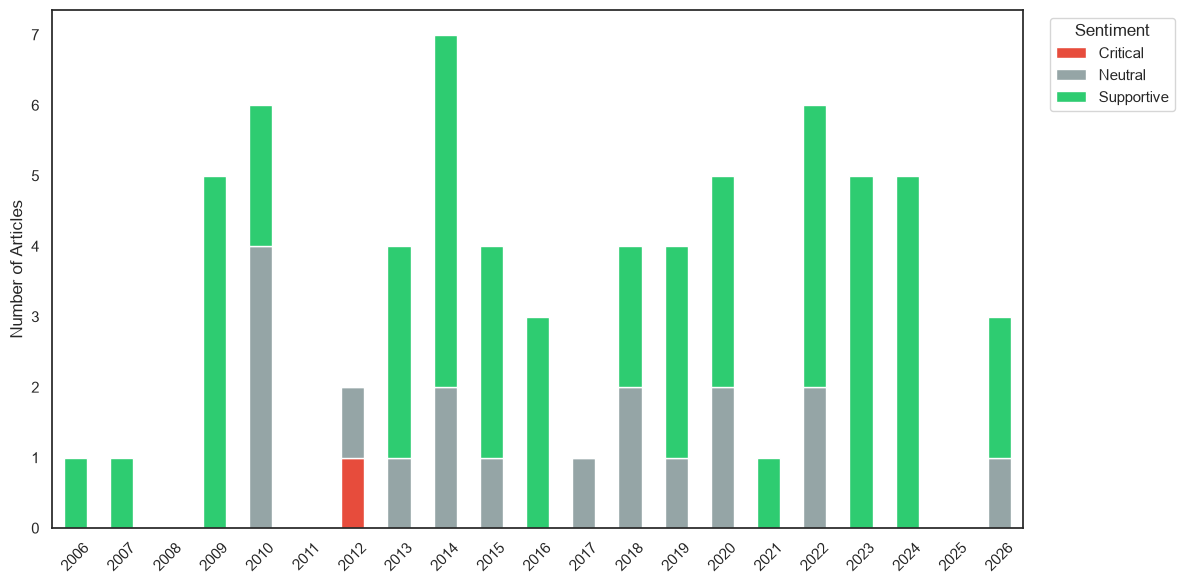

In [3]:
##Sentiment analysis (needs body text)

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from textblob import TextBlob


import re
import pandas as pd
from textblob import TextBlob

# 1. Define your domain-specific words to mask
# (These words appear frequently and carry heavy dictionary sentiment weights)
MASK_WORDS = [
    'restoration', 'restorations', 'restore', 'restoring', 'restored',
    'conservation', 'conserving', 'conserved', 'living',
    'protection', 'protecting', 'protected',
    'enhancement', 'enhancing', 'enhanced'
]

def mask_keywords(text, words_to_mask):
    """
    Replaces domain-specific buzzwords with a neutral placeholder ('project') 
    so they don't skew the general sentiment score.
    """
    if not isinstance(text, str):
        return ""
    
    # Build a case-insensitive regex pattern for whole words
    pattern = r'\b(' + '|'.join(words_to_mask) + r')\b'
    
    # Replace matched words with a neutral word
    masked_text = re.sub(pattern, 'project', text, flags=re.IGNORECASE)
    return masked_text

# 2. Combine with your cascading text fallback (FullText -> Abstract -> Title)
def select_best_text(row):
    for col in ['FullText', 'Abstract', 'Title']:
        val = row.get(col)
        if pd.notna(val):
            val_str = str(val).strip()
            if val_str and val_str.lower() not in ['nan', 'none', 'nat', '']:
                return val_str
    return ""

df['analysis_text'] = df.apply(select_best_text, axis=1)

# 3. Apply keyword masking
df['masked_text'] = df['analysis_text'].apply(lambda x: mask_keywords(x, MASK_WORDS))

# 4. Sentiment classification function
def classify_sentiment(text):
    if not text:
        return 'neutral'
    
    polarity = TextBlob(text).sentiment.polarity
    
    if polarity > 0.05:
        return 'positive'
    elif polarity < -0.05:
        return 'negative'
    else:
        return 'neutral'

# 5. Run sentiment analysis on the masked text
df['sentiment'] = df['masked_text'].apply(classify_sentiment)

# Quick check on how many fallback sources were used
print(df['sentiment'].value_counts())
print(df['Annotation'].value_counts())

# 2. Aggregate counts by year and sentiment category
# sentiment_yearly = pd.crosstab(df['year'], df['sentiment'])
sentiment_yearly = pd.crosstab(df['year'], df['Annotation'])

# Ensure all years from min to max are present so the chart doesn't skip gaps
full_years = range(int(df['year'].min()), int(df['year'].max()) + 1)
sentiment_yearly = sentiment_yearly.reindex(full_years, fill_value=0)

# 3. Plotting a Stacked Bar Chart of Sentiment Over Time
sns.set_theme(style="white")
ax = sentiment_yearly.plot(kind='bar', stacked=True, figsize=(12, 6), color=['#e74c3c', '#95a5a6', '#2ecc71'])

plt.xlabel("", fontsize=12)
plt.ylabel("Number of Articles", fontsize=12)
# plt.legend(["Negative", "Neutral", "Positive"], title="Sentiment", bbox_to_anchor=(1.02, 1), loc='upper left')
plt.legend(["Critical", "Neutral", "Supportive"], title="Sentiment", bbox_to_anchor=(1.02, 1), loc='upper left')

plt.xticks(rotation=45)
plt.tight_layout()

##Save at high res
import os
output_dir = r'F:\Loose figures'
file_name = 'news_sentiment_analysis.tif'

save_path = os.path.join(output_dir, file_name)

# plt.savefig(save_path, bbox_inches='tight', dpi=1000)

plt.show()

In [4]:
neg_df = df[df['Annotation'] == 'Critical']
pos_df = df[df['Annotation'] == 'Supportive']
neutral_df = df[df['Annotation'] == 'Neutral']

# neg_df = df[df['sentiment'] == 'negative']
# pos_df = df[df['sentiment'] == 'positive']
# neutral_df = df[df['sentiment'] == 'neutral']

neg_df ##Port project's spiraling cost seems negative. This doesn't quite make sense
# pos_df

,Title,FullText,Abstract,Annotation,StoreId,ArticleType,Authors,companies,copyright,documentType,...,notes,startPage,subjectClassifications,subjectTerms,subjects,FindACopy,Database,sentiment,analysis_text,masked_text
0,Port project's spiraling price,Costs keep rising to deepen the Savannah River...,Mitigate environmental damage Some Items On ...,Critical,963465691,newspapers,NaN,NaN,"(Copyright , The Atlanta Journal-Constitution...",News,...,NaN,A.8,NaN,NaN,NaN,https://galileo-uga.primo.exlibrisgroup.com/op...,"Global Newsstream Collection, U.S. Newsstream ...",positive,Costs keep rising to deepen the Savannah River...,Costs keep rising to deepen the Savannah River...


In [5]:
print(df['ArticleType'].value_counts())
print(df['copyright'].value_counts())

print(len(df['copyright']))

ArticleType
newspapers                     66
Blogs, Podcasts, & Websites     1
Name: count, dtype: int64
copyright
Targeted News Service                                                                                                                                                                                                                                                                                                                                                                                                                                                  15
Copyright © Targeted News Service. All Rights Reserved.                                                                                                                                                                                                                                                                                                                                                                                   

In [6]:
import pandas as pd
import re
import matplotlib.pyplot as plt
import seaborn as sns

def extract_clean_source(text):
    if not isinstance(text, str) or pd.isna(text):
        return "Other / Unknown"
    
    text_lower = text.lower()
    
    # Keyword mapping rules (order matters: specific outlets first)
    if 'atlanta journal' in text_lower or 'ajc' in text_lower:
        return 'Atlanta Journal-Constitution'
    elif 'savannah morning news' in text_lower:
        return 'Savannah Morning News'
    elif 'brunswick news' in text_lower:
        return 'The Brunswick News'
    elif 'targeted news service' in text_lower:
        return 'Targeted News Service'
    elif 'associated press' in text_lower or ' ap ' in text_lower:
        return 'Associated Press'
    elif 'augusta chronicle' in text_lower:
        return 'The Augusta Chronicle'
    else:
        # Fallback: extract main text inside parentheses if present, or label as Other
        match = re.search(r'\((.*?)\)', text)
        if match:
            return match.group(1).replace('Copyright', '').strip()
        return 'Other Regional / Syndicated'

# Create a clean source column in your dataframe
df['clean_source'] = df['copyright'].apply(extract_clean_source)

# Inspect the cleaned counts
print(df['clean_source'].value_counts())

clean_source
Targeted News Service           20
The Brunswick News              17
Savannah Morning News           15
Other Regional / Syndicated     11
Atlanta Journal-Constitution     3
Syndigate.info                   1
Name: count, dtype: int64


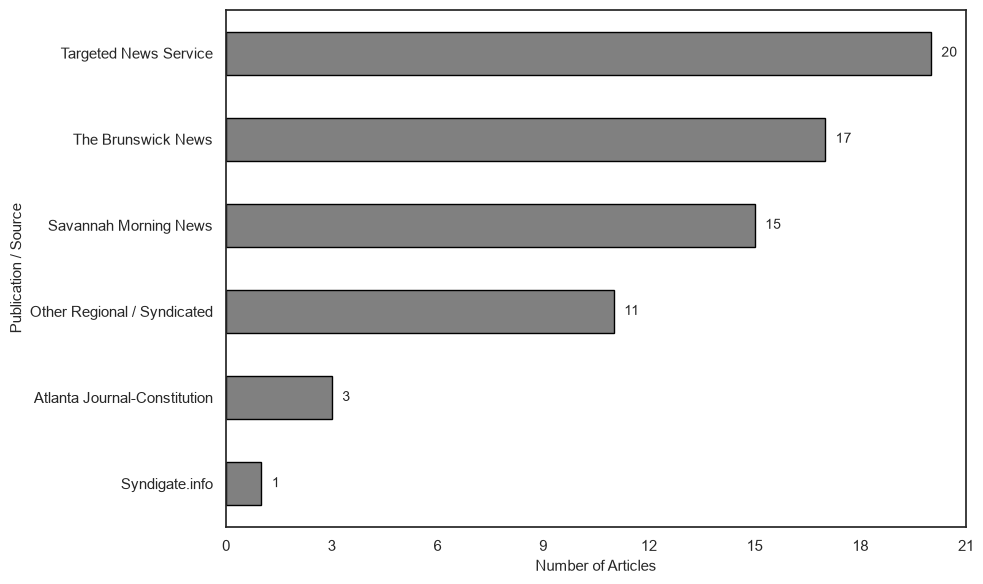

In [7]:
from matplotlib.ticker import MaxNLocator
# Aggregate source counts
source_counts = df['clean_source'].value_counts().sort_values(ascending=True)

# Plotting
plt.figure(figsize=(10, 6))
sns.set_theme(style="white")

# Horizontal bar plot
ax = source_counts.plot(kind='barh', color='gray', edgecolor='black')

plt.xlabel("Number of Articles", fontsize=11)
plt.ylabel("Publication / Source", fontsize=11)

ax.xaxis.set_major_locator(MaxNLocator(integer=True))

# Annotate exact value counts on the bars
for index, value in enumerate(source_counts):
    plt.text(value + 0.3, index, str(value), va='center', fontsize=10)

plt.tight_layout()

##Save at high res
import os
output_dir = r'F:\Loose figures'
file_name = 'news_sources.tif'

save_path = os.path.join(output_dir, file_name)

# plt.savefig(save_path, bbox_inches='tight', dpi=1000)

plt.show()

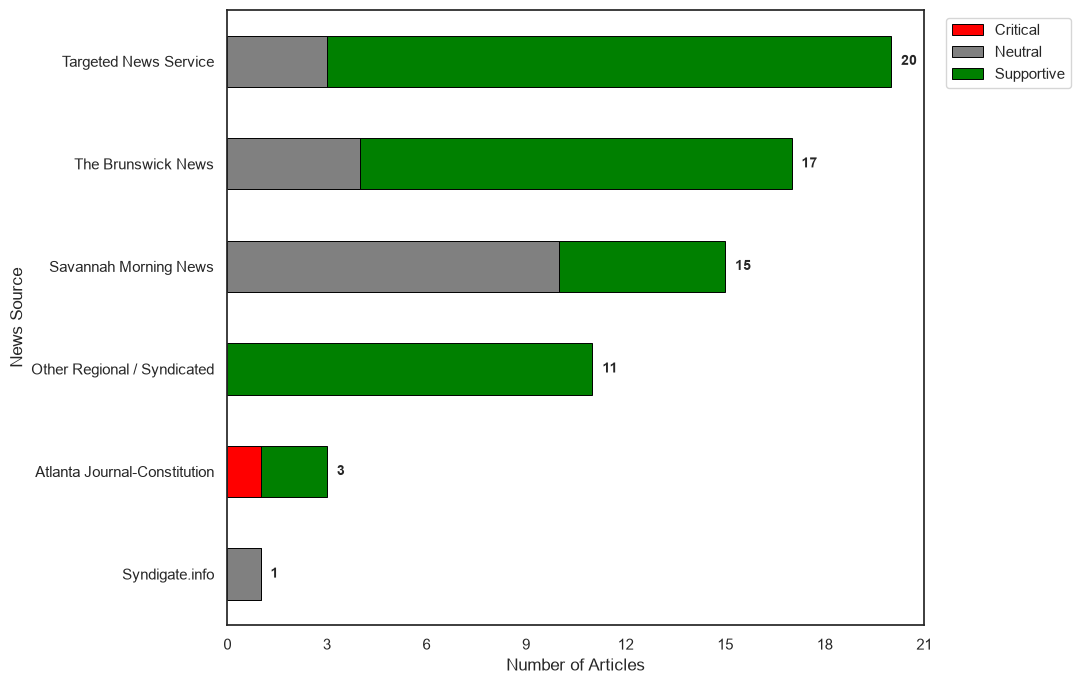

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import seaborn as sns

# Set clean aesthetic style
sns.set_theme(style="white")

# 1. Summarize Annotation counts by Source (Cross-tabulation)
# This creates a table where rows are news sources and columns are Annotation types
source_annotation_counts = pd.crosstab(df['clean_source'], df['Annotation'])

# 2. Sort by total article count per source so the largest sources sit at the top
source_annotation_counts['total'] = source_annotation_counts.sum(axis=1)
source_annotation_counts = source_annotation_counts.sort_values(by='total', ascending=True)
source_annotation_counts = source_annotation_counts.drop(columns=['total'])

# 3. Plotting the Stacked Horizontal Bar Chart
fig, ax = plt.subplots(figsize=(11, 7))

# Plot stacked bars (choose a clear, accessible color palette like 'Set2', 'Viridis', or custom hex)
colors = ['red', 'gray', 'green']
source_annotation_counts.plot(
    kind='barh', 
    stacked=True, 
    ax=ax, 
    color=colors[:len(source_annotation_counts.columns)],
    edgecolor='black',
    linewidth=0.7
)

# 4. Format Chart & Axes
plt.xlabel("Number of Articles", fontsize=12)
plt.ylabel("News Source", fontsize=12)

# Ensure integer-only ticks on the x-axis
ax.xaxis.set_major_locator(MaxNLocator(integer=True))

# Place legend cleanly outside the main plot area
plt.legend(title="", bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)

# 5. Optional: Annotate total counts at the end of each bar
for index, (source, row) in enumerate(source_annotation_counts.iterrows()):
    total_val = row.sum()
    if total_val > 0:
        ax.text(total_val + 0.3, index, str(int(total_val)), va='center', fontsize=10, fontweight='bold')

plt.tight_layout()

##Save at high res
import os
output_dir = r'F:\Loose figures'
file_name = 'news_sources_sentimentaccru.tif'

save_path = os.path.join(output_dir, file_name)

# plt.savefig(save_path, bbox_inches='tight', dpi=1000)

plt.show()

In [8]:
# import os

# df
# out_dir = os.path.expanduser('~/Downloads')
# out_csv = os.path.join(out_dir, 'backup_news.csv')
####### df.to_csv(out_csv, index = False)